# DHVC 통계 시각화 — Re$_{\delta^*}$ 수렴·검증

MPM-STD `apps/dhvc` 출력(상수물성 OB, fig7)을 시각화한다. 참조 MPM-STD_C 와
출력 형식이 달라 새로 작성 — 우리는 **monitor.csv 가 아니라 로그**에 시계열을,
`dhvc_stats_<step>.dat` 에 **U(z) 프로파일**을 쓴다.

- **로그** `logs/dhvc_<Ra>_<jobid>.log` — 열: step · time · dt · max|div| · Re_dstar(누적) · u_max · sec/step
- **stats** `out_<Ra>/dhvc_stats_<step>.dat` — 헤더에 Re_dstar, 본문 `z  U_mean` (시간·xy 평균)
- **검증**: Re$_{\delta^*}$ = u_max·δ*/ν vs `PaScaL_TCS.csv` (Ra→Re_dstar)

**플롯할 케이스는 아래 `CASES` 리스트에서 직접 지정한다** (자동 수집 아님) — 한 줄에
라벨·로그 파일·stats 폴더. 로그가 아직 없는 케이스(예: 큐 대기 중인 런)는 건너뛰고
알려 준다. 같은 Ra 라도 라벨만 다르면 따로 그린다 (1e8 value 벽 vs mirror 벽 재시작).

실행하면 같은 폴더에 `dhvc_timeseries.png` · `dhvc_profiles.png` · `dhvc_validation.png`
로 저장하고 inline 으로도 띄운다.

In [33]:
import os, re, glob, csv
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")   # 노트북: 저장 + 화면
except NameError:
    matplotlib.use("Agg")                                   # 스크립트/배치
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 10})

APP_DIR = "/shared/home/wel1come1234/workspace/MPM-STD/apps/dhvc"
if not os.path.isdir(os.path.join(APP_DIR, "plot")):
    APP_DIR = os.path.dirname(os.getcwd())   # plot/ 에서 실행 시 상위
PLOT_DIR = os.path.join(APP_DIR, "plot")
print("APP_DIR =", APP_DIR)

APP_DIR = /shared/home/wel1come1234/workspace/MPM-STD/apps/dhvc


In [34]:
# ── 파서 ──────────────────────────────────────────────────────────────────
def parse_log(path):
    """dhvc 로그 → {step,time,dt,div,re_dstar,u_max, settings}.
    '# step' 헤더 뒤 7열 숫자행 + 로그 앞머리의 **설정 에코**.
    ⚠ stats_start_time 은 ini 가 아니라 이 에코에서 읽는다 — ini 는 런 이후
    수정됐을 수 있다 (실제로 1e7 은 잡 35592 가 60, 35593 이 100 이다)."""
    cols = {k: [] for k in ("step", "time", "dt", "div", "re_dstar", "u_max")}
    settings, settings_text, nu_header = {}, {}, None
    for line in open(path):
        matched = re.match(r"\s*(\w+)\s*=\s*([-\d.eE+]+)\s*$", line)
        if matched and matched.group(1) not in settings:   # 첫 에코만 (뒤는 무시)
            settings[matched.group(1)] = float(matched.group(2))
        quoted = re.match(r'\s*(\w+)\s*=\s*"(.*)"\s*$', line)   # stats_dir 등
        if quoted and quoted.group(1) not in settings_text:
            settings_text[quoted.group(1)] = quoted.group(2)
        if nu_header is None and line.startswith("# DHVC"):        # 솔버가 쓴 nu
            found = re.search(r"nu=([-\d.eE+]+)", line)
            if found: nu_header = float(found.group(1))
        parts = line.split()
        if len(parts) == 7 and not line.lstrip().startswith("#"):
            try:
                v = [float(x) for x in parts]
            except ValueError:
                continue
            cols["step"].append(v[0]); cols["time"].append(v[1]); cols["dt"].append(v[2])
            cols["div"].append(v[3]); cols["re_dstar"].append(v[4]); cols["u_max"].append(v[5])
    if not cols["step"]:
        return None
    log = {k: np.array(v) for k, v in cols.items()}
    log["settings"] = settings
    log["settings_text"] = settings_text
    log["nu_header"] = nu_header
    log["path"] = path
    return log

def parse_stats(path):
    """dhvc_stats_*.dat → dict(step,time,re_dstar, z, U). 헤더 3줄(#)."""
    header = {}
    for line in open(path):
        if line.startswith("#"):
            for k, val in re.findall(r"(\w+)=([-\d.eE+]+)", line):
                header[k] = float(val)
            continue
            break
    data = np.loadtxt(path, comments="#")
    return dict(step=int(header.get("step", 0)), time=header.get("t", 0.0),
                re_dstar=header.get("Re_dstar", float("nan")),
                z=data[:, 0], U=data[:, 1])

def reynolds_delta_star(z, U, nu):
    """Re_δ* = u_max·δ*/ν (솔버 정의 1:1) — 프로파일에서 재계산(검산용)."""
    kmax = int(np.argmax(U)); u_max = U[kmax]
    if u_max <= 0: return 0.0, 0, 0.0
    zc = np.concatenate(([0.0], z[:kmax + 1]))
    f = np.concatenate(([1.0], 1.0 - U[:kmax + 1] / u_max))
    dstar = np.trapezoid(f, zc)
    return u_max * dstar / nu, kmax, dstar

def attach_window(case):
    """통계 누적 구간 [t_start, t_end] 를 복원해 case 에 붙인다.

    DHVC 누적은 **dt 가중**이라 (main.cpp:342-345  sum_u += u_bar*dt; sum_dt += dt)
    sum_dt 가 정확히 t_end − t_start 로 망원합된다 → dt 가중 평균 = 그 구간의
    단순 시간평균이고, 구간 길이가 곧 평균 시간이다.

    t_start 정본 : 로그 설정 에코의 stats_start_time (그 런이 실제로 쓴 값)
    독립 검증   : Re_dstar 열은 sum_dt<=0 이면 0 이므로(main.cpp:256 running_re_delta)
                  처음 0 을 벗어나는 모니터 행이 시작을 monitor_interval 안으로 가둔다
    t_end       : 최신 stats 헤더의 t (stats 가 없으면 로그 마지막 t = 누적 진행 중)
    """
    log, stats = case["log"], case["stats"]
    time, re_dstar = log["time"], log["re_dstar"]
    positive = np.flatnonzero(re_dstar > 0)
    if positive.size:                      # [직전 행, 첫 양수 행] 으로 시작을 괄호
        first = int(positive[0])
        bracket = (float(time[first - 1]) if first > 0 else float(time[0]),
                   float(time[first]))
    else:
        bracket = None
    start_setting = log["settings"].get("stats_start_time")
    if bracket is None and start_setting is None:
        case["window"] = None; return None
    if bracket is None:                    # 아직 누적 전 — 예정 시작만 안다
        case["window"] = dict(start=start_setting, end=None, duration=0.0,
                              source="settings echo (not started yet)",
                              bracket=None, started=False, n_snapshots=len(stats),
                              end_step=None)
        return case["window"]
    if start_setting is not None and bracket[0] - 1e-9 <= start_setting <= bracket[1] + 1e-9:
        start, source = start_setting, "settings echo (confirmed by Re_dstar>0)"
    elif start_setting is not None:
        start, source = bracket[1], "Re_dstar>0 (settings echo disagrees)"
        print(f"  [{case['label']}] ⚠ stats_start_time={start_setting:g} 이 "
              f"Re_dstar>0 괄호 [{bracket[0]:.3f}, {bracket[1]:.3f}] 밖이다 "
              f"— 로그 쪽을 쓴다")
    else:
        start, source = bracket[1], "Re_dstar>0 (no settings echo)"
    end = stats[-1]["time"] if stats else float(time[-1])
    end_step = stats[-1]["step"] if stats else int(log["step"][-1])
    # 마지막 stats 쓰기는 **마지막 스텝**에 일어나므로 모니터 마지막 행
    # (monitor_interval 간격) 보다 최대 한 간격만큼 뒤설 수 있다 — 정상이다.
    gap = 2 * float(np.median(np.diff(time))) if time.size > 1 else 0.0
    if stats and not (time[0] - gap <= stats[-1]["time"] <= time[-1] + gap):
        print(f"  [{case['label']}] ⚠ 최신 stats t={stats[-1]['time']:.1f} 가 이 로그의 "
              f"t 범위 [{time[0]:.1f}, {time[-1]:.1f}] (±{gap:.1f}) 밖 "
              f"— 다른 잡이 쓴 파일일 수 있다")
    case["window"] = dict(start=start, end=end, duration=end - start, source=source,
                          bracket=bracket, started=True, n_snapshots=len(stats),
                          end_step=end_step)
    return case["window"]

def window_text(case, short=False):
    """그림 꼬리말 한 줄 — ASCII 만 (DejaVu Sans 에 한글 글리프 없음).
    short=True 는 좁은 그림(6.4in)용 축약형 — 긴 형식은 폭을 넘친다."""
    window = case["window"]
    label = f"Ra={case['label']}"
    if window is None:
        return f"{label}: stats window unknown (no Re_dstar>0 row, no settings echo)"
    if not window["started"]:
        return (f"{label}: stats not started yet - accumulation begins at "
                f"t={window['start']:.1f} (now t={case['log']['time'][-1]:.1f})")
    if short:
        return (f"{label}: avg over t {window['start']:.1f}-{window['end']:.1f}"
                f"  (sum_dt {window['duration']:.1f}, "
                f"{window['n_snapshots']} snaps)")
    text = (f"{label}: dt-weighted average over t {window['start']:.1f}"
            f"-{window['end']:.1f}  (sum_dt = {window['duration']:.1f}")
    if window["n_snapshots"]:
        text += f", {window['n_snapshots']} snapshots, last step {window['end_step']}"
    else:
        text += ", running - no stats file yet"
    return text + f", {window['source']})"

def annotate_windows(figure, annotated, fontsize=7, short=False):
    """모든 그림 하단에 '어디서 어디까지 평균했나' 를 같은 형식으로 적는다."""
    figure.text(0.5, 0.006, "\n".join(window_text(c, short) for c in annotated),
                ha="center", va="bottom", fontsize=fontsize, color="0.35",
                linespacing=1.5)

def shade_window(axis, case, color=None, alpha=0.10):
    """누적 구간을 음영 띠 + 점선 경계로. 아직 시작 전이면 시작선만 긋는다."""
    window = case["window"]
    if window is None:
        return
    if not window["started"]:
        axis.axvline(window["start"], color=color or "tab:purple", lw=0.9, ls="--",
                     alpha=0.7)
        return
    axis.axvspan(window["start"], window["end"], color=color or "tab:purple",
                 alpha=alpha, zorder=0)
    for boundary in (window["start"], window["end"]):
        axis.axvline(boundary, color=color or "tab:purple", lw=0.8, ls=":", zorder=1)

# Ra 라벨 → 수치 (폴백 — 가능하면 case_physics 가 로그 에코를 쓴다)
def ra_value(label):
    """라벨 앞머리의 지수 표기만 읽는다 — '1e8_4gpu' 처럼 꼬리표가 붙어도 된다."""
    matched = re.match(r"\s*(\d+(?:\.\d+)?[eE][+-]?\d+)", label)
    if not matched:
        raise ValueError(f"라벨에서 Ra 를 못 읽었다: {label!r}")
    return float(matched.group(1))

def case_physics(log, label, app_dir):
    """Ra·Pr·nu·stats 디렉터리를 **로그 에코에서** 읽는다 (라벨 규칙보다 우선).

    ⚠ 라벨로 out_<label> 을 찾으면 빗나간다 — 1e8_4gpu 런의 stats_dir 은
    'apps/dhvc/out_1e8' 이라 같은 Ra 의 2-GPU 런과 **같은 폴더를 공유**한다.
    nu 는 솔버가 머리글에 찍은 값을 그대로 쓰고(없으면 sqrt(Pr/Ra) 폴백),
    stats 경로는 basename 만 떼어 app_dir 밑으로 붙인다 (에코는 repo 루트 기준)."""
    settings, text = log["settings"], log["settings_text"]
    rayleigh = settings.get("rayleigh") or ra_value(label)
    prandtl = settings.get("prandtl", 0.7)
    nu = log["nu_header"] if log["nu_header"] else (prandtl / rayleigh) ** 0.5
    stats_dir = os.path.join(app_dir, os.path.basename(text["stats_dir"])) \
        if "stats_dir" in text else os.path.join(app_dir, f"out_{label}")
    return rayleigh, prandtl, nu, stats_dir

# 참조 Re_dstar (PaScaL_TCS.csv: Ra, Re_dstar)
ref = {}
pth = os.path.join(PLOT_DIR, "PaScaL_TCS.csv")
if os.path.exists(pth):
    for row in csv.reader(open(pth)):
        if len(row) == 2:
            ref[float(row[0])] = float(row[1])
def reference_re(ra, tol=0.3):
    for k, v in ref.items():
        if abs(k / ra - 1) < tol: return v
    return None
print("참조 Re_dstar:", {f"{k:.0e}": round(v, 3) for k, v in ref.items()})

참조 Re_dstar: {'1e+05': 5.378, '1e+06': 10.43, '1e+07': 22.947, '1e+08': 43.122, '1e+09': 62.963, '1e+10': 89.078}


In [ ]:
# ── 플롯할 케이스를 여기서 직접 지정한다 (리스트 순서 = 범례·표 순서) ──────────
#   label  : 그림·표 이름. 앞머리의 Ra 지수 표기(1e8 …)는 로그 에코가 없을 때만 폴백으로 읽는다
#   log    : 로그 파일 (APP_DIR 기준). 글롭이면 **가장 최근 수정된 1개**
#   stats  : 프로파일 폴더 (APP_DIR 기준). 생략하면 로그 에코의 stats_dir 을 쓴다
#   color / marker : 생략 가능 (기본 tab10 순서 / "o")
# 빼고 싶은 케이스는 줄을 지우거나 주석 처리하면 된다.
CASES = [
    dict(label="1e5",        log="logs/dhvc_1e5_35578.log",            stats="out_1e5"),
    dict(label="1e6",        log="logs/dhvc_1e6_35579.log",            stats="out_1e6"),
    dict(label="1e7",        log="logs/dhvc_1e7_35593.log",            stats="out_1e7"),
    dict(label="1e8 4gpu",   log="logs/dhvc_1e8_4gpu_35641.log",       stats="out_1e8",
         marker="o"),                                                  # value 벽, t 0-150
    dict(label="1e8 mirror", log="logs/dhvc_1e8_4gpu_mirror_35834.log", stats="out_1e8_mirror",
         marker="s"),                                                  # ck_00180000(t=121.66) 재시작, mirror 벽
]

def load_case(spec, index):
    """CASES 한 줄 → case dict. 로그가 없거나 숫자 행이 없으면 None (메시지 출력)."""
    label = spec["label"]
    matches = sorted(glob.glob(os.path.join(APP_DIR, spec["log"])), key=os.path.getmtime)
    if not matches:
        print(f"[{label}] 로그 없음 — 건너뜀 ({spec['log']})"); return None
    log_path = matches[-1]
    log = parse_log(log_path)
    if log is None:
        print(f"[{label}] 로그에 아직 모니터 행이 없음 — 건너뜀 ({os.path.basename(log_path)})")
        return None
    found_job = re.search(r"_(\d+)\.log$", os.path.basename(log_path))
    job = found_job.group(1) if found_job else "?"
    ra, pr, nu, stats_dir = case_physics(log, label, APP_DIR)
    if "stats" in spec:
        stats_dir = os.path.join(APP_DIR, spec["stats"])
    sfiles = sorted(glob.glob(os.path.join(stats_dir, "dhvc_stats_*.dat")),
                    key=lambda p: int(re.search(r"(\d+)", os.path.basename(p)).group(1)))
    stats = [parse_stats(p) for p in sfiles]
    return dict(label=label, job=job, log=log, stats=stats, ra=ra, nu=nu, prandtl=pr,
                stats_dir=stats_dir, log_path=log_path,
                color=spec.get("color", plt.cm.tab10(index % 10)),
                marker=spec.get("marker", "o"))

cases = {}
for index, spec in enumerate(CASES):
    case = load_case(spec, index)
    if case is None: continue
    assert case["label"] not in cases, f"라벨이 겹친다: {case['label']!r}"
    cases[case["label"]] = case
    attach_window(case)
    log = case["log"]
    last_re = log["re_dstar"][-1] if len(log["re_dstar"]) else float("nan")
    tgt = reference_re(case["ra"])
    tgt_s = f"{tgt:.3f} ({100*(last_re/tgt-1):+.1f}%)" if tgt and last_re else "—"
    print(f"[{case['label']:>10}] job {case['job']}: 로그 {len(log['step'])}행 "
          f"t={log['time'][0]:.1f}-{log['time'][-1]:.1f} Re_dstar(누적)={last_re:.3f}  "
          f"vs PaScaL {tgt_s}  / stats {len(case['stats'])}개 "
          f"({os.path.relpath(case['stats_dir'], APP_DIR)}/)")
    print(f"             누적 구간: {window_text(case)}")
assert cases, "로드된 DHVC 케이스가 없다 — 런이 아직 통계를 안 썼을 수 있음"
colors = {lab: c["color"] for lab, c in cases.items()}   # CASES 의 color (기본 tab10 순서)

# ── 누적 구간 요약 표 ─────────────────────────────────────────────────────
# 같은 stats 폴더를 두 케이스가 공유하면 프로파일이 어느 런 것인지 모호해진다
#   (1e8 2-GPU 런과 1e8_4gpu 런이 둘 다 out_1e8 에 쓴다)
shared = {}
for lab, c in cases.items():
    shared.setdefault(c["stats_dir"], []).append(lab)
for stats_dir, labels in shared.items():
    if len(labels) > 1 and cases[labels[0]]["stats"]:
        print(f"⚠ {os.path.basename(stats_dir)}/ 를 {', '.join(labels)} 가 공유한다 "
              f"— 프로파일이 어느 런 것인지 헤더 t 로 확인할 것")

print("\n" + "=" * 103)
print(f"{'case':>12s} {'job':>7s} {'t(log)':>9s} {'stats window t':>18s} "
      f"{'sum_dt':>8s} {'snaps':>6s} {'Re_dstar':>9s} {'PaScaL':>8s} {'dev':>7s}")
print("-" * 103)
for lab, c in cases.items():
    w = c["window"]
    if w is None:          span, dur = "-- unknown --", "-"
    elif not w["started"]: span, dur = f"starts at {w['start']:.0f}", "0"
    else:                  span, dur = f"{w['start']:.1f}-{w['end']:.1f}", f"{w['duration']:.1f}"
    re_last = c["log"]["re_dstar"][-1]
    tgt = reference_re(c["ra"])
    print(f"{lab:>12s} {c['job']:>7s} {c['log']['time'][-1]:9.1f} {span:>18s} "
          f"{dur:>8s} {len(c['stats']):6d} {re_last:9.3f} "
          f"{(f'{tgt:.3f}' if tgt else '-'):>8s} "
          f"{(f'{100*(re_last/tgt-1):+.1f}%' if tgt and re_last else '-'):>7s}")
print("=" * 103)

## 1. 시계열 — Re$_{\delta^*}$ 수렴·안정성

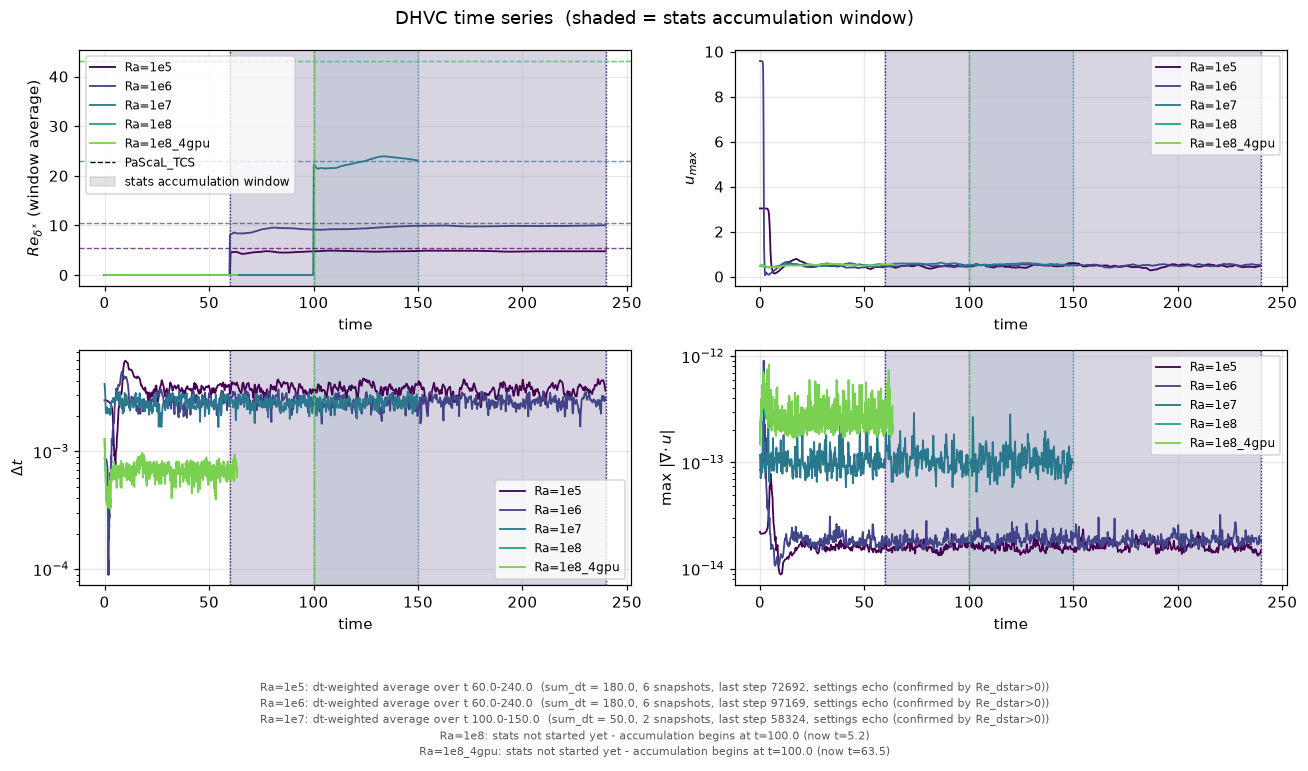

In [36]:
# 그림 안 문자열은 ASCII/mathtext 만 — DejaVu Sans 에 한글 글리프가 없다
panels = [("re_dstar", r"$Re_{\delta^*}$ (window average)", False),
          ("u_max", r"$u_{max}$", False),
          ("dt", r"$\Delta t$", True),
          ("div", r"max $|\nabla\!\cdot u|$", True)]
# 음영 띠 = 각 케이스가 **통계를 누적한 구간** (케이스 색, 네 패널 공통) —
# 평균 구간 동안 dt·div 가 멀쩡했는지 같은 x축에서 바로 읽힌다.
fig, axes = plt.subplots(2, 2, figsize=(12, 7)); axes = axes.ravel()
for ax, (key, ylab, ylog) in zip(axes, panels):
    for lab, c in cases.items():
        shade_window(ax, c, color=colors[lab], alpha=0.10)
        ax.plot(c["log"]["time"], c["log"][key], color=colors[lab], lw=1.2,
                label=f"Ra={lab}")
    if key == "re_dstar":
        for lab, c in cases.items():
            tgt = reference_re(c["ra"])
            if tgt: ax.axhline(tgt, color=colors[lab], ls="--", lw=0.9, alpha=0.7)
        ax.plot([], [], "k--", lw=0.9, label="PaScaL_TCS")
    if ylog: ax.set_yscale("log")
    ax.set_xlabel("time"); ax.set_ylabel(ylab); ax.legend(fontsize=8)
axes[0].axvspan(np.nan, np.nan, color="0.4", alpha=0.18,
                label="stats accumulation window")   # 범례용 더미
axes[0].legend(fontsize=8)
fig.suptitle("DHVC time series  (shaded = stats accumulation window)")
fig.tight_layout(rect=(0, 0.02 + 0.026 * len(cases), 1, 1))
annotate_windows(fig, cases.values())
fig.savefig(os.path.join(PLOT_DIR, "dhvc_timeseries.png"), dpi=150); plt.show()

## 2. 평균 유속 프로파일 $U(z)$ 와 $\delta^*$

[1e5] 프로파일 Re_dstar=4.791 (u_max=0.4659 @ z=0.0981, δ*=0.0272)  헤더값=4.791
       누적 구간: t 60.0-240.0 (sum_dt 180.0)  |  스냅샷별 구간 끝: 90, 120, 150, 180, 210, 240
[1e6] 프로파일 Re_dstar=10.023 (u_max=0.4991 @ z=0.0749, δ*=0.0168)  헤더값=10.023
       누적 구간: t 60.0-240.0 (sum_dt 180.0)  |  스냅샷별 구간 끝: 90, 120, 150, 180, 210, 240
[1e7] 프로파일 Re_dstar=23.076 (u_max=0.5427 @ z=0.0560, δ*=0.0112)  헤더값=23.076
       누적 구간: t 100.0-150.0 (sum_dt 50.0)  |  스냅샷별 구간 끝: 125, 150
[1e8] stats 아직 없음 — 프로파일 생략 (Ra=1e8: stats not started yet - accumulation begins at t=100.0 (now t=5.2))
[1e8_4gpu] stats 아직 없음 — 프로파일 생략 (Ra=1e8_4gpu: stats not started yet - accumulation begins at t=100.0 (now t=63.5))


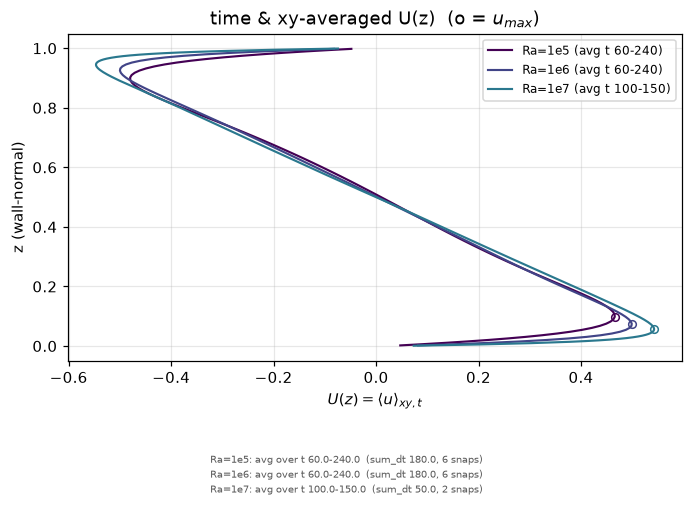

In [37]:
# 각 스냅샷은 **같은 t_start 에서 시작해 그 시각까지 누적**한 러닝 평균이다
# (리셋이 아니다) — 그래서 마지막 스냅샷이 가장 긴 구간 = 가장 수렴된 프로파일.
profiled = [c for c in cases.values() if c["stats"]]
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for lab, c in cases.items():
    if not c["stats"]:
        print(f"[{lab}] stats 아직 없음 — 프로파일 생략 "
              f"({window_text(c)})"); continue
    s = c["stats"][-1]                      # 최신(가장 긴 구간) 프로파일
    w = c["window"]
    ax.plot(s["U"], s["z"], color=colors[lab], lw=1.4,
            label=f"Ra={lab} (avg t {w['start']:.0f}-{s['time']:.0f})")
    re_chk, kmax, dstar = reynolds_delta_star(s["z"], s["U"], c["nu"])
    ax.plot(s["U"][kmax], s["z"][kmax], "o", color=colors[lab], ms=5, mfc="none")
    print(f"[{lab}] 프로파일 Re_dstar={re_chk:.3f} (u_max={s['U'][kmax]:.4f} @ z={s['z'][kmax]:.4f}, "
          f"δ*={dstar:.4f})  헤더값={s['re_dstar']:.3f}")
    print(f"       누적 구간: t {w['start']:.1f}-{s['time']:.1f} "
          f"(sum_dt {s['time'] - w['start']:.1f})  |  스냅샷별 구간 끝: "
          + ", ".join(f"{snapshot['time']:.0f}" for snapshot in c["stats"]))
ax.set_xlabel(r"$U(z)=\langle u\rangle_{xy,t}$"); ax.set_ylabel("z (wall-normal)")
ax.set_title(r"time & xy-averaged U(z)  (o = $u_{max}$)")
ax.legend(fontsize=8)
fig.tight_layout(rect=(0, 0.02 + 0.042 * max(len(profiled), 1), 1, 1))
annotate_windows(fig, profiled, fontsize=6.5, short=True)
fig.savefig(os.path.join(PLOT_DIR, "dhvc_profiles.png"), dpi=150); plt.show()

## 3. 검증 — Re$_{\delta^*}$(Ra) vs 참조

In [ ]:
fig, ax = plt.subplots(figsize=(5.4, 4.6))
ras = np.array(sorted(ref)); res = np.array([ref[r] for r in ras])
ax.plot(ras, res, "ks-", ms=5, mfc="white", lw=1, label="PaScaL_TCS (reference)")
for lab, c in cases.items():
    re_last = c["log"]["re_dstar"][-1]
    w = c["window"]
    if not (w and w["started"]):           # 아직 누적 전이면 점을 찍을 게 없다
        print(f"[{lab}] 누적 전 — 검증 점 생략 ({window_text(c)})"); continue
    ax.plot(c["ra"], re_last, c["marker"], color=colors[lab], ms=7, alpha=0.6,
            label=f"MPM-STD Ra={lab} (avg t {w['start']:.0f}-{w['end']:.0f})")
ax.set_xscale("log"); ax.set_xlabel("Ra"); ax.set_ylabel(r"$Re_{\delta^*}$")
ax.set_title("DHVC validation: " + r"$Re_{\delta^*}$ vs Ra"
             + "\n(each point = dt-weighted average over its own window)",
             fontsize=10)
ax.legend(fontsize=8)
started = [c for c in cases.values() if c["window"] and c["window"]["started"]]
fig.tight_layout(rect=(0, 0.02 + 0.042 * max(len(started), 1), 1, 1))
annotate_windows(fig, started, fontsize=6.5, short=True)
fig.savefig(os.path.join(PLOT_DIR, "dhvc_validation.png"), dpi=150); plt.show()
print("\n요약 (Re_dstar 는 각 케이스의 누적 구간 평균):")
for lab, c in cases.items():
    tgt = reference_re(c["ra"]); re_last = c["log"]["re_dstar"][-1]
    dev = f"{100*(re_last/tgt-1):+.1f}%" if tgt else "—"
    w = c["window"]
    span = (f"t {w['start']:.1f}-{w['end']:.1f}, sum_dt {w['duration']:.1f}"
            if w and w["started"] else "누적 전")
    print(f"  Ra={lab:>10}: Re_dstar={re_last:7.3f}  참조 "
          f"{(f'{tgt:.3f}' if tgt else '-'):>7s}  편차 {dev:>7s}  [{span}]")